# 18 · Variational Autoencoders and Probabilistic Generative Modeling

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/18-vae/18_vae.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-18-vae.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 18](https://github.com/anuxlab/deep-learning-systems/wiki/Module-18) |
| **Level** | Advanced |
| **Typical CPU runtime** | ~1–2 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 03, 16 |

## What you will do

- Derive the ELBO and verify it numerically on a model with a known evidence.
- Verify the closed-form Gaussian KL and the reparameterisation trick (gradients flow through sampling).
- Train a VAE on digits; visualise the 2-D latent space and a decoded manifold.
- Run a β-VAE sweep to see the reconstruction–regularisation trade-off, and diagnose posterior collapse.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:16:13 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926845498
          commit: 30206410b37c093a0d326d94f81e5fd7c94a76ce


## 1 · The ELBO
We want $\log p_\theta(x)=\log\int p_\theta(x|z)p(z)\,dz$, which is intractable for neural decoders. For any $q_\phi(z|x)$:
$$\log p_\theta(x)=\underbrace{\mathbb E_{q}[\log p_\theta(x|z)]-D_{KL}(q_\phi(z|x)\,\|\,p(z))}_{\text{ELBO}}+D_{KL}(q_\phi(z|x)\,\|\,p_\theta(z|x)).$$
The last term is $\ge0$, so ELBO $\le\log p(x)$ with equality iff $q$ equals the true posterior. We test this identity on a **linear-Gaussian model** where *everything is analytic*: $z\sim\mathcal N(0,1)$, $x|z\sim\mathcal N(az,\sigma^2)$ ⇒ $x\sim\mathcal N(0,a^2+\sigma^2)$ and $z|x\sim\mathcal N\big(\tfrac{a x}{a^2+\sigma^2},\tfrac{\sigma^2}{a^2+\sigma^2}\big)$.

In [2]:
from scipy import stats
a, sig, x0 = 1.5, .5, 2.0
logpx = stats.norm(0, np.sqrt(a**2 + sig**2)).logpdf(x0); pm, pv = a * x0 / (a**2 + sig**2), sig**2 / (a**2 + sig**2)
def kl_gauss(m1, v1, m2, v2): return .5 * (np.log(v2 / v1) + (v1 + (m1 - m2)**2) / v2 - 1)
def elbo(mq, vq):
    # E_q[log N(x0; a z, sig^2)] has a closed form: -0.5 log(2π σ²) - ((x0 - a·mq)² + a²·vq) / (2σ²)
    rec = -.5 * np.log(2 * np.pi * sig**2) - ((x0 - a * mq) ** 2 + a**2 * vq) / (2 * sig**2); return rec - kl_gauss(mq, vq, 0., 1.)
print(f"log p(x) = {logpx:.5f}")
e_opt = elbo(pm, pv); print(f"ELBO with the TRUE posterior q=N({pm:.3f},{pv:.3f}): {e_opt:.5f}")
check(abs(e_opt - logpx) < 1e-9, "ELBO equals log p(x) when q is the exact posterior")
gap = []
for mq, vq in [(0, 1), (.5, .3), (pm + .5, pv), (pm, pv * 3)]:
    e = elbo(mq, vq); g = kl_gauss(mq, vq, pm, pv); gap.append((e, logpx - e, g)); print(f"q=N({mq:.2f},{vq:.2f}): ELBO {e:.4f}  gap logp-ELBO {logpx-e:.4f}  KL(q||posterior) {g:.4f}")
    check(abs((logpx - e) - g) < 1e-9, "gap = KL(q || true posterior)  — the ELBO identity holds")

log p(x) = -2.17708
ELBO with the TRUE posterior q=N(1.200,0.100): -2.17708
  ✅ ELBO equals log p(x) when q is the exact posterior
q=N(0.00,1.00): ELBO -12.7258  gap logp-ELBO 10.5487  KL(q||posterior) 10.5487
  ✅ gap = KL(q || true posterior)  — the ELBO identity holds
q=N(0.50,0.30): ELBO -5.0778  gap logp-ELBO 2.9007  KL(q||posterior) 2.9007
  ✅ gap = KL(q || true posterior)  — the ELBO identity holds
q=N(1.70,0.10): ELBO -3.4271  gap logp-ELBO 1.2500  KL(q||posterior) 1.2500
  ✅ gap = KL(q || true posterior)  — the ELBO identity holds
q=N(1.20,0.30): ELBO -2.6278  gap logp-ELBO 0.4507  KL(q||posterior) 0.4507
  ✅ gap = KL(q || true posterior)  — the ELBO identity holds


## 2 · Closed-form KL and the reparameterisation trick
For a diagonal Gaussian encoder $q=\mathcal N(\mu,\mathrm{diag}\,\sigma^2)$ and standard-normal prior: $D_{KL}=\tfrac12\sum_j(\mu_j^2+\sigma_j^2-\log\sigma_j^2-1)$.

**Reparameterisation:** sampling $z\sim q_\phi$ is not differentiable w.r.t. $\phi$, but $z=\mu+\sigma\odot\epsilon$, $\epsilon\sim\mathcal N(0,I)$ is — gradients flow through $\mu,\sigma$. Check: for $\mathbb E_{z\sim\mathcal N(\mu,\sigma^2)}[z^2]=\mu^2+\sigma^2$ the pathwise gradients must equal $2\mu$ and $2\sigma$.

In [3]:
mu, lv = torch.randn(6, 4), torch.randn(6, 4)
kl_cf = .5 * (mu**2 + lv.exp() - lv - 1).sum(1)
kl_torch = torch.distributions.kl_divergence(torch.distributions.Normal(mu, (.5 * lv).exp()), torch.distributions.Normal(0., 1.)).sum(1)
check(torch.allclose(kl_cf, kl_torch, atol=1e-5), "closed-form KL(q||N(0,I)) == torch.distributions")
m = torch.tensor(1.3, requires_grad=True); s = torch.tensor(.7, requires_grad=True); eps = torch.randn(2_000_000)
((m + s * eps) ** 2).mean().backward(); print(f"pathwise grads: dm={m.grad:.3f} (2μ={2*1.3})  ds={s.grad:.3f} (2σ={2*.7})")
check(abs(m.grad - 2.6) < .02 and abs(s.grad - 1.4) < .02, "reparameterised gradients are unbiased")
z_bad = torch.normal(m.detach(), s.detach()); print("direct sampling has no gradient path:", z_bad.requires_grad)
check(not z_bad.requires_grad, "naive sampling blocks gradients — hence reparameterisation")

  ✅ closed-form KL(q||N(0,I)) == torch.distributions
pathwise grads: dm=2.599 (2μ=2.6)  ds=1.399 (2σ=1.4)
  ✅ reparameterised gradients are unbiased
direct sampling has no gradient path: False
  ✅ naive sampling blocks gradients — hence reparameterisation


## 3 · A VAE on digits
Encoder $x\to(\mu,\log\sigma^2)$, decoder $z\to\hat x\in[0,1]^{64}$ (sigmoid). Loss (negative ELBO) = Bernoulli reconstruction BCE (summed over pixels) + $\beta\cdot$KL. We use $\beta=1$ first with a 2-D latent so we can plot it.

18:16:18 | INFO | vae_beta1 took 4.46s


test: recon 22.07 nats  KL 2.36 nats  -ELBO 24.44
  ✅ negative ELBO decreases during training


18:16:19 | INFO | figure saved -> figures/vae_latent_space.png


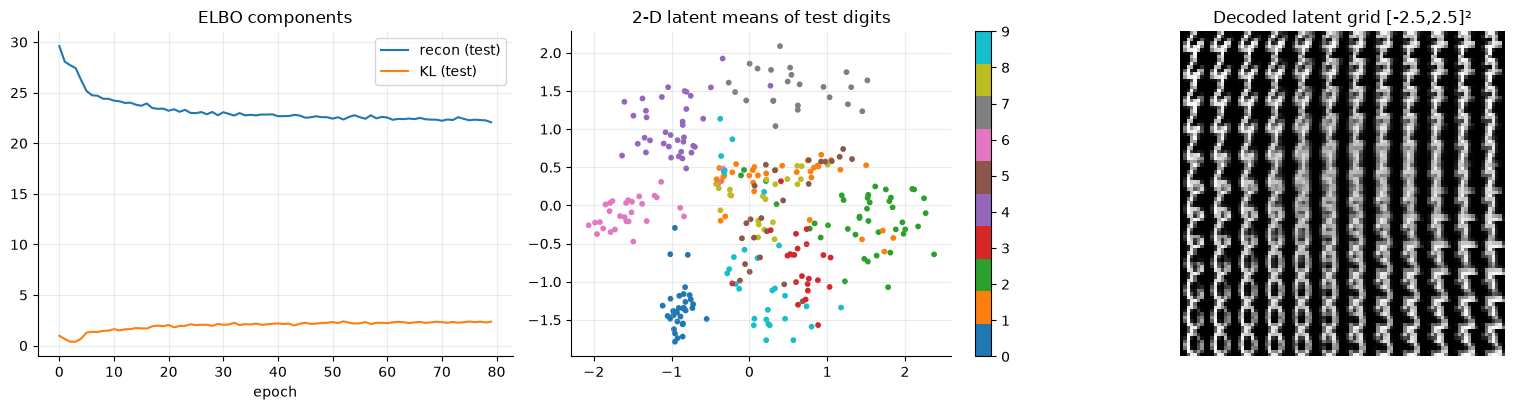

In [4]:
from sklearn.datasets import load_digits
D = load_digits(); X = torch.tensor(D.data / 16., dtype=torch.float32); y = D.target; idx = np.random.default_rng(0).permutation(len(X)); tr, te = idx[:1500], idx[1500:]; Xtr, Xte, yte = X[tr], X[te], y[te]
class VAE(nn.Module):
    def __init__(s, k=2, h=128): super().__init__(); s.enc = nn.Sequential(nn.Linear(64, h), nn.ReLU()); s.mu, s.lv = nn.Linear(h, k), nn.Linear(h, k); s.dec = nn.Sequential(nn.Linear(k, h), nn.ReLU(), nn.Linear(h, 64)); s.k = k
    def encode(s, x): h = s.enc(x); return s.mu(h), s.lv(h)
    def forward(s, x): mu, lv = s.encode(x); z = mu + (.5 * lv).exp() * torch.randn_like(mu); return s.dec(z), mu, lv
def vae_loss(m, x, beta=1., fb=0.):
    lg, mu, lv = m(x); rec = F.binary_cross_entropy_with_logits(lg, x, reduction="none").sum(1); kl = .5 * (mu**2 + lv.exp() - lv - 1).sum(0)      # KL per latent dim (summed over batch below)
    kl_tot = torch.clamp(kl / len(x), min=fb).sum(); return rec.mean() + beta * kl_tot, rec.mean().item(), (kl.sum() / len(x)).item()
def train_vae(k=2, beta=1., epochs=80, seed=0, anneal=0, fb=0.):
    torch.manual_seed(seed); m = VAE(k); o = torch.optim.Adam(m.parameters(), 2e-3); H = []
    for ep in range(epochs):
        b_ = beta * min(1., (ep + 1) / anneal) if anneal else beta; perm = torch.randperm(len(Xtr)); tl = tr_ = tk = 0; n = 0
        for s in range(0, len(perm), 64):
            xb = Xtr[perm[s:s + 64]]; l, r, k_ = vae_loss(m, xb, b_, fb); o.zero_grad(); l.backward(); o.step(); tr_ += r * len(xb); tk += k_ * len(xb); n += len(xb)
        with torch.no_grad(): lt, rt, kt = vae_loss(m, Xte, 1.0)
        H.append((tr_ / n, tk / n, rt, kt))
    return m, np.array(H)
with timer("vae_beta1"): vae, H = train_vae()
print(f"test: recon {H[-1,2]:.2f} nats  KL {H[-1,3]:.2f} nats  -ELBO {H[-1,2]+H[-1,3]:.2f}")
check(H[-1, 2] + H[-1, 3] < H[0, 2] + H[0, 3], "negative ELBO decreases during training")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2)); ax[0].plot(H[:, 2], label="recon (test)"); ax[0].plot(H[:, 3], label="KL (test)"); ax[0].legend(); ax[0].set_xlabel("epoch"); ax[0].set_title("ELBO components")
with torch.no_grad(): mu_te, _ = vae.encode(Xte)
sc = ax[1].scatter(mu_te[:, 0], mu_te[:, 1], c=yte, cmap="tab10", s=10); plt.colorbar(sc, ax=ax[1]); ax[1].set_title("2-D latent means of test digits")
g = np.linspace(-2.5, 2.5, 12); canvas = np.zeros((12 * 8, 12 * 8))
with torch.no_grad():
    for i, zy in enumerate(g[::-1]):
        for j, zx in enumerate(g): canvas[i*8:(i+1)*8, j*8:(j+1)*8] = torch.sigmoid(vae.dec(torch.tensor([[zx, zy]], dtype=torch.float32))).view(8, 8).numpy()
ax[2].imshow(canvas, cmap="gray"); ax[2].axis("off"); ax[2].set_title("Decoded latent grid [-2.5,2.5]²")
show("vae_latent_space"); METRICS["vae_beta1"] = dict(recon=H[-1, 2], kl=H[-1, 3])

### Generation from the prior and a latent interpolation
Because the KL term pulls the aggregate posterior toward $\mathcal N(0,I)$, **sampling $z\sim\mathcal N(0,I)$ and decoding** yields plausible digits; interpolating between two codes gives smooth morphs.

18:16:19 | INFO | figure saved -> figures/vae_samples.png


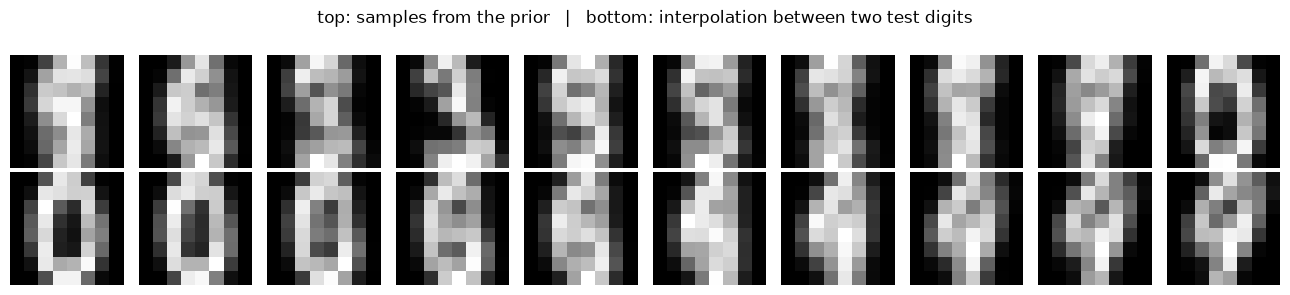

aggregate posterior mean/std per dim: [ 0.05 -0.03] [1.02 0.91]
  ✅ aggregate posterior is roughly centred / unit-scale (matches the prior)


In [5]:
torch.manual_seed(3)
with torch.no_grad():
    samples = torch.sigmoid(vae.dec(torch.randn(16, 2))); z0, z1 = vae.encode(Xte[:1])[0], vae.encode(Xte[1:2])[0]; ts = torch.linspace(0, 1, 10)[:, None]; inter = torch.sigmoid(vae.dec(z0 * (1 - ts) + z1 * ts))
fig, ax = plt.subplots(2, 10, figsize=(13, 3))
for i in range(10): ax[0, i].imshow(samples[i].view(8, 8) if i < 16 else None, cmap="gray"); ax[1, i].imshow(inter[i].view(8, 8), cmap="gray"); ax[0, i].axis("off"); ax[1, i].axis("off")
plt.suptitle("top: samples from the prior   |   bottom: interpolation between two test digits"); show("vae_samples")
agg_mean, agg_std = mu_te.mean(0), mu_te.std(0); print("aggregate posterior mean/std per dim:", agg_mean.numpy().round(2), agg_std.numpy().round(2))
check(agg_std.abs().max() < 2.5 and agg_mean.abs().max() < .6, "aggregate posterior is roughly centred / unit-scale (matches the prior)")

## 4 · β-VAE: the trade-off knob
$\mathcal L=\text{recon}+\beta\,\mathrm{KL}$. Small $\beta$ ⇒ sharper reconstructions, less regular latent space; large $\beta$ ⇒ stronger compression/disentanglement pressure, blurrier outputs and eventually **posterior collapse** (the encoder ignores $x$; KL≈0). We use an 8-D latent and count *active units* (dimensions with non-trivial KL).

β=  0.1: recon  17.02  KL  13.77  active latent dims 8/8


β=  1.0: recon  21.22  KL   3.12  active latent dims 5/8


β=  4.0: recon  27.12  KL   0.00  active latent dims 0/8


β= 16.0: recon  27.15  KL   0.00  active latent dims 0/8
18:16:29 | INFO | beta_sweep took 9.70s


18:16:29 | INFO | figure saved -> figures/beta_vae.png


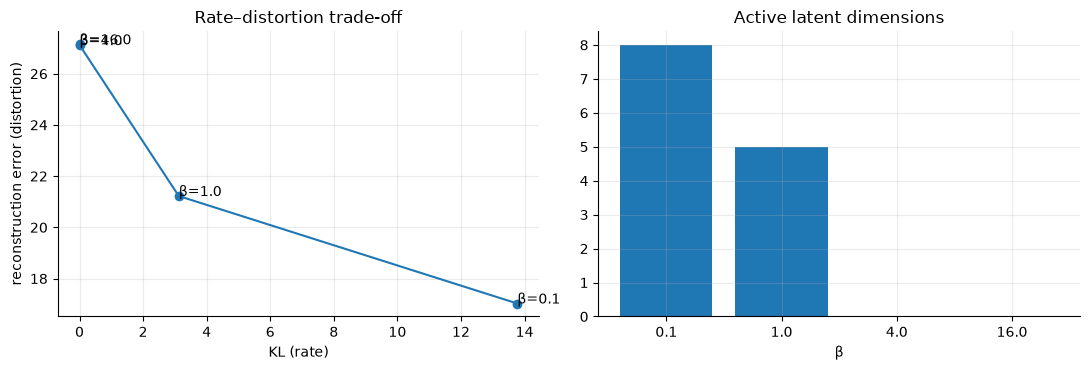

  ✅ higher β: lower KL but worse reconstruction
  ✅ higher β activates fewer latent units


In [6]:
betas = [0.1, 1.0, 4.0, 16.0]; res = {}
with timer("beta_sweep"):
    for b in betas:
        m, Hh = train_vae(k=8, beta=b, epochs=60)
        with torch.no_grad(): lg, mu, lv = m(Xte); klvec = .5 * (mu**2 + lv.exp() - lv - 1).mean(0)
        res[b] = dict(recon=Hh[-1, 2], kl=Hh[-1, 3], active=int((klvec > .05).sum())); print(f"β={b:5}: recon {res[b]['recon']:6.2f}  KL {res[b]['kl']:6.2f}  active latent dims {res[b]['active']}/8")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); ax[0].plot([res[b]["kl"] for b in betas], [res[b]["recon"] for b in betas], "o-")
for b in betas: ax[0].annotate(f"β={b}", (res[b]["kl"], res[b]["recon"]))
ax[0].set_xlabel("KL (rate)"); ax[0].set_ylabel("reconstruction error (distortion)"); ax[0].set_title("Rate–distortion trade-off"); ax[1].bar([str(b) for b in betas], [res[b]["active"] for b in betas]); ax[1].set_title("Active latent dimensions"); ax[1].set_xlabel("β")
show("beta_vae"); check(res[16.0]["kl"] < res[.1]["kl"] and res[16.0]["recon"] > res[.1]["recon"], "higher β: lower KL but worse reconstruction")
check(res[16.0]["active"] <= res[.1]["active"], "higher β activates fewer latent units"); METRICS["beta_sweep"] = res

## 5 · Posterior collapse and remedies
With a very strong decoder (or large β) the optimum can be $q(z|x)=p(z)$ — latents carry no information. Standard fixes: **KL annealing** (ramp β from 0→1 over the first epochs) and **free bits** (don't penalise KL below $\lambda$ nats per dimension). We provoke collapse with β=8 and compare annealing + free bits at the same final β using the *information* measure: mutual information proxy = KL on test data and kNN accuracy of the latent means.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
def knn_acc(m):
    with torch.no_grad(): a, b = m.encode(Xtr)[0].numpy(), m.encode(Xte)[0].numpy()
    return KNeighborsClassifier(5).fit(a, y[tr]).score(b, yte)
cfgs = {"β=8, plain": dict(beta=8.), "β=8, KL-anneal 30ep": dict(beta=8., anneal=30), "β=8, free bits 0.5": dict(beta=8., fb=.5)}; out = {}
with timer("collapse_remedies"):
    for nm, kw in cfgs.items(): m, Hh = train_vae(k=8, epochs=60, **kw); out[nm] = (Hh[-1, 3], knn_acc(m)); print(f"{nm:22s} test KL {out[nm][0]:6.2f} nats   latent kNN acc {out[nm][1]:.3f}")
check(out["β=8, free bits 0.5"][0] > out["β=8, plain"][0], "free bits keeps more information in the latent code (higher KL)")
METRICS["collapse_remedies"] = {k: dict(kl=v[0], knn=v[1]) for k, v in out.items()}

β=8, plain             test KL   0.00 nats   latent kNN acc 0.687


β=8, KL-anneal 30ep    test KL   0.00 nats   latent kNN acc 0.488


β=8, free bits 0.5     test KL   3.68 nats   latent kNN acc 0.946
18:16:37 | INFO | collapse_remedies took 7.33s


  ✅ free bits keeps more information in the latent code (higher KL)


In [8]:
save_metrics("18", METRICS)
log.info('notebook 18 finished OK')

18:16:37 | INFO | metrics saved -> metrics.json


18:16:37 | INFO | notebook 18 finished OK


## Wrap-up

## Exercises (do these next)

1. Replace the Bernoulli likelihood by a Gaussian with learned variance; what changes about sample sharpness?
2. Train a conditional VAE (concatenate the one-hot label to encoder and decoder inputs) and generate a requested digit.
3. Estimate log p(x) with importance sampling (IWAE) using 100 samples and compare with the ELBO.

## Where to read more

- Wiki chapter: [Module 18](https://github.com/anuxlab/deep-learning-systems/wiki/Module-18) (derivations, worked example, Q&A).
- Kingma & Welling (2014) *Auto-Encoding Variational Bayes*; Higgins et al. (2017) β-VAE; Bowman et al. (2016) KL annealing; Kingma et al. (2016) free bits; Doersch (2016) *Tutorial on VAEs*.